## PIP

In [ ]:
!pip install yfinance numpy pandas statsmodels matplotlib seaborn pykalman

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.5/248.5 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.5/141.5 kB 5.7 MB/s eta 0:00:00


## Model price forecast

In [ ]:
import yfinance as yf
import pandas as pd

# ดึงข้อมูลราคาหุ้น AAPL
ticker = "AAPL"
df = yf.download(ticker, period="1y", interval="1d")

# เลือกเฉพาะคอลัมน์ 'Close'
df = df[['Close']]
df.dropna(inplace=True)
df.tail()


[*********************100%***********************]  1 of 1 completed


Price,Close
Ticker,AAPL
Date,
2025-02-19,244.869995
2025-02-20,245.830002
2025-02-21,245.550003
2025-02-24,247.100006
2025-02-25,247.039993


In [ ]:
from statsmodels.tsa.ar_model import AutoReg

# กำหนด Lookback Length (ถ้าใช้ Auto ให้เลือกค่า Correlation ที่ดีที่สุด)
LOOKBACK_LENGTH = 150
FORECAST_DAYS = 14

# Train Model
train_data = df['Close'][-LOOKBACK_LENGTH:]
model = AutoReg(train_data, lags=5)  # ใช้ AutoRegressive Model
model_fit = model.fit()

# Forecast
forecast_values = model_fit.predict(start=len(train_data), end=len(train_data) + FORECAST_DAYS - 1)
forecast_dates = pd.date_range(df.index[-1], periods=FORECAST_DAYS+1, freq='D')[1:]

# สร้าง DataFrame ของผลลัพธ์
forecast_df = pd.DataFrame({'Date': forecast_dates, 'Forecast': forecast_values})
forecast_df.set_index('Date', inplace=True)


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/deterministic.py:308: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a unit increment support extending. The index is set will contain the po

In [ ]:
import numpy as np

# คำนวณ Correlation
correlation = np.corrcoef(train_data[:-1], train_data[1:])[0, 1]

# คำนวณ R²
r2 = correlation ** 2

# ค่ามากสุดและน้อยสุดของ Forecast
max_forecast = forecast_values.max()
min_forecast = forecast_values.min()

# แสดงผล Model Statistics
print(f"Correlation: {correlation:.2f}")
print(f"R²: {r2:.3f}")
print(f"Max Forecasted Value: {max_forecast:.2f}")
print(f"Min Forecasted Value: {min_forecast:.2f}")
print(f"Lookback Length: {LOOKBACK_LENGTH}")


Correlation: nan
R²: nan
Max Forecasted Value: 246.71
Min Forecasted Value: 241.22
Lookback Length: 150


/usr/local/lib/python3.11/dist-packages/numpy/lib/function_base.py:2889: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/usr/local/lib/python3.11/dist-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/usr/local/lib/python3.11/dist-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


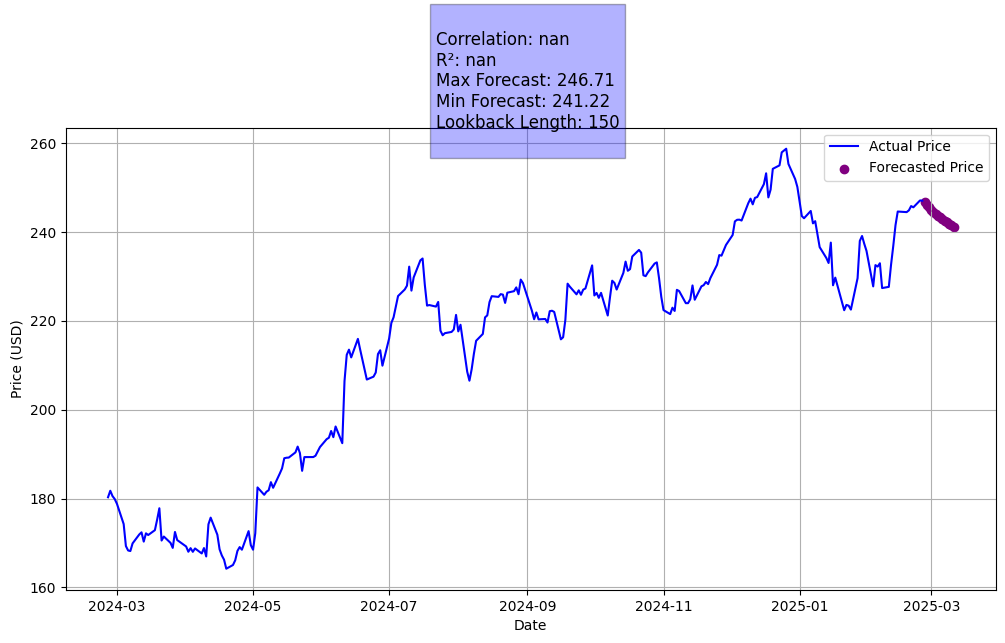

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ตั้งค่าขนาดกราฟ
plt.figure(figsize=(12,6))

# Plot ราคาจริง
plt.plot(df.index, df['Close'], label='Actual Price', color='blue')

# Plot Forecast (Scatter Plot)
plt.scatter(forecast_df.index, forecast_df['Forecast'], label='Forecasted Price', color='purple', marker='o')

# Plot Forecast (Line Plot)
plt.plot(forecast_df.index, forecast_df['Forecast'], color='purple', linestyle='dashed')

# แสดง Model Statistics บนกราฟ
stats_text = f"""
Correlation: {correlation:.2f}
R²: {r2:.3f}
Max Forecast: {max_forecast:.2f}
Min Forecast: {min_forecast:.2f}
Lookback Length: {LOOKBACK_LENGTH}
"""
plt.text(df.index[-LOOKBACK_LENGTH], df['Close'].max(), stats_text, fontsize=12, bbox=dict(facecolor='blue', alpha=0.3))

# ตั้งค่ากราฟ
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid()

# แสดงผล
plt.show()


## Model kalman forecast

[*********************100%***********************]  1 of 1 completed
<ipython-input-14-fae0e2d1d7cc>:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.dropna(inplace=True)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, callin

Correlation: 1.00
R²: 0.998
Max Forecasted Value: 239.96
Min Forecasted Value: 238.00
Lookback Length: 150
Forecast Trend: Downtrend


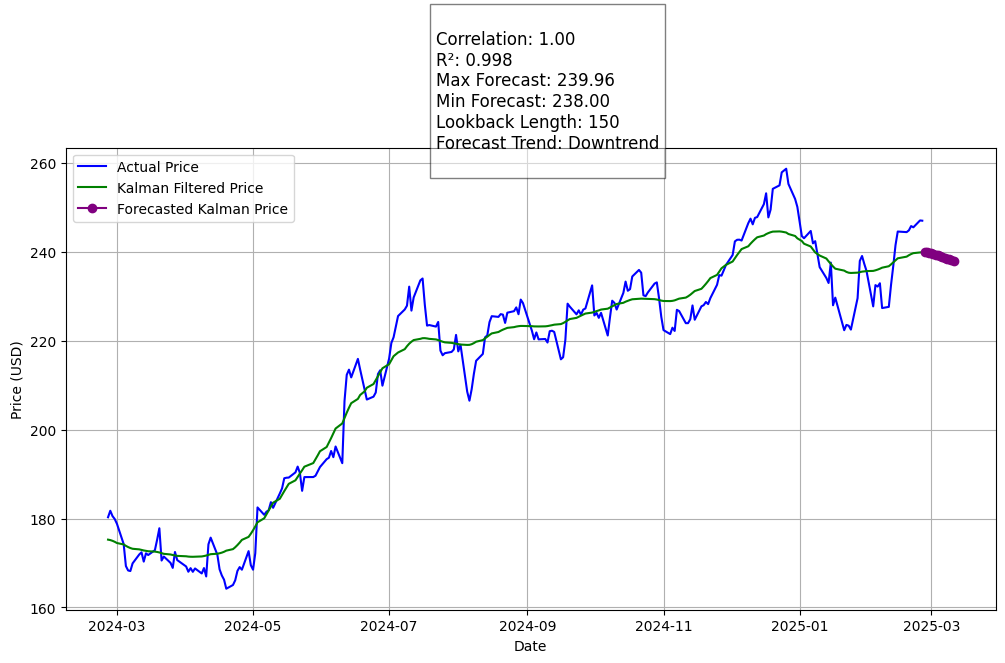

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.ar_model import AutoReg
from pykalman import KalmanFilter

# ดึงข้อมูลราคาหุ้น AAPL
ticker = "AAPL"
df = yf.download(ticker, period="1y", interval="1d")

# เลือกเฉพาะคอลัมน์ 'Close'
df = df[['Close']]
df.dropna(inplace=True)

# ======= ขั้นตอน Kalman Filter =======
kf = KalmanFilter(
    transition_matrices=[1],
    observation_matrices=[1],
    initial_state_mean=df['Close'].iloc[0],
    initial_state_covariance=1,
    observation_covariance=1,
    transition_covariance=0.01
)

state_means, _ = kf.smooth(df['Close'].values)
df['Kalman_Filtered'] = state_means.flatten()
# ======================================

# กำหนด Lookback Length และ Forecast Days
LOOKBACK_LENGTH = 150
FORECAST_DAYS = 14

# Train โมเดลโดยใช้ Kalman Filtered Data
train_data = df['Kalman_Filtered'][-LOOKBACK_LENGTH:]
model = AutoReg(train_data, lags=5)
model_fit = model.fit()

# Forecast
forecast_values = model_fit.predict(start=len(train_data), end=len(train_data) + FORECAST_DAYS - 1)
forecast_dates = pd.date_range(df.index[-1], periods=FORECAST_DAYS+1, freq='D')[1:]

# สร้าง DataFrame สำหรับ Forecast
forecast_df = pd.DataFrame({'Date': forecast_dates, 'Forecast': forecast_values})
forecast_df.set_index('Date', inplace=True)

# ======= ฟังก์ชันวิเคราะห์แนวโน้ม =======
def detect_trend(forecast_values):
    # Check if forecast_values is empty
    if len(forecast_values) == 0:
        return "No trend data available"

    first = forecast_values.values[0] # Access the first element of the numpy array
    last = forecast_values.values[-1] # Access the last element of the numpy array

    if last > first and np.all(np.diff(forecast_values.values) > 0):
        return "Uptrend"
    elif last < first and np.all(np.diff(forecast_values.values) < 0):
        return "Downtrend"
    else:
        return "Sideways"
# วิเคราะห์แนวโน้มของช่วง Forecast
trend_result = detect_trend(forecast_values)
# ======================================

# คำนวณ Correlation และ R²
correlation = np.corrcoef(train_data[:-1], train_data[1:])[0, 1]
r2 = correlation ** 2

# ค่ามากสุดและน้อยสุดของ Forecast
max_forecast = forecast_values.max()
min_forecast = forecast_values.min()

# แสดงผล Model Statistics และแนวโน้ม
print(f"Correlation: {correlation:.2f}")
print(f"R²: {r2:.3f}")
print(f"Max Forecasted Value: {max_forecast:.2f}")
print(f"Min Forecasted Value: {min_forecast:.2f}")
print(f"Lookback Length: {LOOKBACK_LENGTH}")
print(f"Forecast Trend: {trend_result}")

# ======= Plot กราฟ =======
plt.figure(figsize=(12,6))

# Plot ราคาจริง
plt.plot(df.index, df['Close'], label='Actual Price', color='blue')

# Plot ราคาที่ผ่านการกรองด้วย Kalman Filter
plt.plot(df.index, df['Kalman_Filtered'], label='Kalman Filtered Price', color='green')

# Plot Forecast
plt.plot(forecast_df.index, forecast_df['Forecast'], label='Forecasted Kalman Price', color='purple', marker='o')
plt.plot(forecast_df.index, forecast_df['Forecast'], color='purple', linestyle='dashed')

# แสดง Model Statistics และแนวโน้มบนกราฟ
stats_text = f"""
Correlation: {correlation:.2f}
R²: {r2:.3f}
Max Forecast: {max_forecast:.2f}
Min Forecast: {min_forecast:.2f}
Lookback Length: {LOOKBACK_LENGTH}
Forecast Trend: {trend_result}
"""
plt.text(df.index[-LOOKBACK_LENGTH], df['Close'].max(), stats_text, fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# ตั้งค่ากราฟ
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid()
plt.show()

## Model FEPFP ยังระเบิดอยู่

[*********************100%***********************]  1 of 1 completed
<ipython-input-45-394dbf00a36b>:31: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  z[0] = x[0] - xm[0]
<ipython-input-45-394dbf00a36b>:36: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  z[1] = x[1] - xm[1] + alpha * z[0]
<ipython-input-45-394dbf00a36b>:40: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  z[i] = x[i] - xm[i] + alpha * z[i-1] - z[i-2]
<ipython-input-45-394dbf00a36b>:89: DeprecationWarnin

ปรับ npast จาก 300 เป็น 151 เนื่องจากข้อมูลที่มีอยู่ไม่พอ.


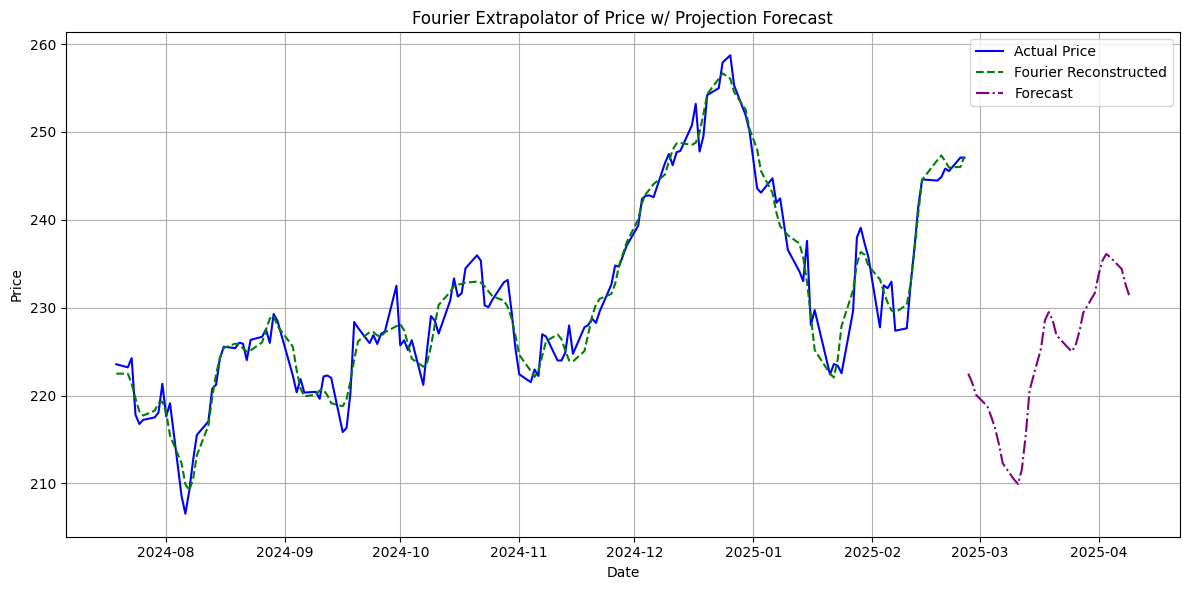

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from pandas.tseries.offsets import BDay

def fourier_extrapolation(x, npast, nfut, nharm, frqtol):
    """
    ทำ Fourier Extrapolation เพื่อสร้างการ reconstruct ข้อมูลอดีตและ forecast
    Parameters:
      x      : ข้อมูลราคาที่จะนำมาคำนวณ (numpy array) ควรมีขนาด npast
      npast  : จำนวนบาร์ที่ใช้ในการคำนวณย้อนหลัง
      nfut   : จำนวนบาร์ที่ต้องการ forecast (ผลลัพธ์จะมี nfut+1 จุด)
      nharm  : จำนวน Harmonics ที่จะใช้ (loop for harmonic components)
      frqtol : ค่าความแม่นยำสำหรับการหาค่า frequency (tolerance)
    Returns:
      xm : ข้อมูลที่ reconstruct สำหรับอดีต (numpy array ขนาด npast)
      ym : forecast series (numpy array ขนาด nfut+1)
    """
    # เริ่มต้นด้วยค่าเฉลี่ยของข้อมูลเป็น baseline
    av = np.mean(x)
    xm = np.full(npast, av, dtype=float)
    ym = np.full(nfut+1, av, dtype=float)

    # Loop สำหรับแต่ละ harmonic
    for harm in range(1, nharm + 1):
        # เริ่มต้น iterative algorithm เพื่อหา frequency โดยใช้วิธี Quinn & Fernandes
        alpha = 0.0
        beta = 2.0
        z = np.zeros(npast, dtype=float)
        z[0] = x[0] - xm[0]

        while abs(alpha - beta) > frqtol:
            alpha = beta
            if npast > 1:
                z[1] = x[1] - xm[1] + alpha * z[0]
            num = z[0] * z[1] if npast > 1 else 0.0
            den = z[0] * z[0] if npast > 0 else 1.0
            for i in range(2, npast):
                z[i] = x[i] - xm[i] + alpha * z[i-1] - z[i-2]
                num += z[i-1] * (z[i] + z[i-2])
                den += z[i-1]**2
            beta = num / den if den != 0 else beta

        # คำนวณ frequency w (รัศมีของ harmonic)
        w = np.arccos(np.clip(beta/2.0, -1.0, 1.0))

        # คำนวณค่าสัมประสิทธิ์โดยใช้ Least-Squares Fitting
        n = npast
        Sc = Ss = Scc = Sss = Scs = Sx = Sxc = Sxs = 0.0
        for i in range(npast):
            c = np.cos(w * i)
            s = np.sin(w * i)
            dx = x[i] - xm[i]
            Sc  += c
            Ss  += s
            Scc += c * c
            Sss += s * s
            Scs += c * s
            Sx  += dx
            Sxc += dx * c
            Sxs += dx * s
        Sc  /= n
        Ss  /= n
        Scc /= n
        Sss /= n
        Scs /= n
        Sx  /= n
        Sxc /= n
        Sxs /= n

        if w == 0:
            m = Sx
            a = 0.0
            b = 0.0
        else:
            denominator = (Scs - Sc*Ss)**2 - (Scc - Sc**2) * (Sss - Ss**2)
            if denominator == 0:
                m = Sx
                a = 0.0
                b = 0.0
            else:
                a = ((Sxs - Sx*Ss) * (Scs - Sc*Ss) - (Sxc - Sx*Sc) * (Sss - Ss**2)) / denominator
                b = ((Sxc - Sx*Sc) * (Scs - Sc*Ss) - (Sxs - Sx*Ss) * (Scc - Sc**2)) / denominator
                m = Sx - a*Sc - b*Ss

        # Update ค่า reconstruction (xm) สำหรับข้อมูลอดีต และ update forecast (ym)
        for i in range(npast):
            xm[i] = xm[i] + m + a * np.cos(w * i) + b * np.sin(w * i)
            if i <= nfut:
                ym[nfut - i] = ym[nfut - i] + m + a * np.cos(w * i) - b * np.sin(w * i)

    # กลับด้าน forecast ให้ได้ลำดับที่ถูกต้อง (จากอดีตไปอนาคต)
    ym = ym[::-1]
    return xm, ym

def main():
# 1. ดึงข้อมูลราคา (ใช้ yfinance)
    ticker = "AAPL"
    df = yf.download(ticker, period="1y", interval="1d")

    # ใช้คอลัมน์ 'Close' เป็นข้อมูลราคา
    src_series = df['Close'].dropna().values
    dates = df.index  # date index สำหรับข้อมูลย้อนหลัง


# 2. กำหนด Parameter สำหรับ Fourier Extrapolator
    npast_input = 300        # จำนวนบาร์ที่ใช้ในการคำนวณย้อนหลังที่ต้องการ
    nharm = 20               # จำนวน Harmonics ที่ใช้
    frqtol = 0.0001          # Frequency Tolerance
    nfut = 30                # จำนวนบาร์ที่ต้องการ forecast
    backbars = 100           # เลื่อนข้อมูลย้อนหลัง (index offset)

    # ตรวจสอบให้แน่ใจว่ามีข้อมูลเพียงพอ
    available = len(src_series) - backbars
    npast = min(npast_input, available)
    if npast < npast_input:
        print(f"ปรับ npast จาก {npast_input} เป็น {npast} เนื่องจากข้อมูลที่มีอยู่ไม่พอ.")

    # ดึงข้อมูลย้อนหลังจาก src_series และ date index
    x = src_series[backbars:backbars+npast].astype(float)
    past_dates = dates[backbars:backbars+npast]


# 3. คำนวณ Fourier Extrapolation
    xm, ym = fourier_extrapolation(x, npast, nfut, nharm, frqtol)

# 4. สร้าง Date Index สำหรับ Forecast
#ใช้วันทำการ (Business Days) สำหรับ forecast โดยเริ่มจากวันถัดไปจากวันสุดท้ายใน past_dates
    last_date = past_dates[-1]
    forecast_dates = pd.bdate_range(start=last_date + BDay(1), periods=nfut+1)

# 5. Visualization: Plot ผลลัพธ์
    plt.figure(figsize=(12, 6))
    plt.plot(past_dates, x, label="Actual Price", color="blue")
    plt.plot(past_dates, xm, label="Fourier Reconstructed", color="green", linestyle="--")
    plt.plot(forecast_dates, ym, label="Forecast", color="purple", linestyle="-.")

    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.title("Fourier Extrapolator of Price w/ Projection Forecast")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()
